In [18]:
%pip install matplotlib
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [19]:
# Importing libraries and seting the file path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)

file_path = r'C:\Users\LENOVO\OneDrive\OneDrive - National College of Ireland\Machine_learning_Project\dataSet\raw_dataset\Housing_dataset\Residential Property Price Register\PPR-ALL.csv'

In [20]:
#Read the CSV file
#The file uses `latin-1` encoding, because the € sign and Irish letters (á, ú) break the normal encoding.
ppr = pd.read_csv(file_path, encoding='latin-1', low_memory=False)

print(ppr.shape)   # (rows, columns)
ppr.head()

(811646, 9)


,Date of Sale (dd/mm/yyyy),Address,County,Eircode,Price (),Not Full Market Price,VAT Exclusive,Description of Property,Property Size Description
0,01/01/2010,"5 Braemor Drive, Churchtown, Co.Dublin",Dublin,NaN,"343,000.00",No,No,Second-Hand Dwelling house /Apartment,NaN
1,03/01/2010,"134 Ashewood Walk, Summerhill Lane, Portlaoise",Laois,NaN,"185,000.00",No,Yes,New Dwelling house /Apartment,greater than or equal to 38 sq metres and less...
2,04/01/2010,"1 Meadow Avenue, Dundrum, Dublin 14",Dublin,NaN,"438,500.00",No,No,Second-Hand Dwelling house /Apartment,NaN
3,04/01/2010,"1 The Haven, Mornington",Meath,NaN,"400,000.00",No,No,Second-Hand Dwelling house /Apartment,NaN
4,04/01/2010,"11 Melville Heights, Kilkenny",Kilkenny,NaN,"160,000.00",No,No,Second-Hand Dwelling house /Apartment,NaN


In [21]:
## Step 3: Rename columns to short, simple names
#The original names are long and the € sign shows as a strange symbol.

print('Original names:', list(ppr.columns))

ppr.columns = ['sale_date', 'address', 'county', 'eircode', 'price',
               'not_full_market_price', 'vat_exclusive', 'property_description', 'property_size']

ppr.head()

Original names: ['Date of Sale (dd/mm/yyyy)', 'Address', 'County', 'Eircode', 'Price (\x80)', 'Not Full Market Price', 'VAT Exclusive', 'Description of Property', 'Property Size Description']


,sale_date,address,county,eircode,price,not_full_market_price,vat_exclusive,property_description,property_size
0,01/01/2010,"5 Braemor Drive, Churchtown, Co.Dublin",Dublin,NaN,"343,000.00",No,No,Second-Hand Dwelling house /Apartment,NaN
1,03/01/2010,"134 Ashewood Walk, Summerhill Lane, Portlaoise",Laois,NaN,"185,000.00",No,Yes,New Dwelling house /Apartment,greater than or equal to 38 sq metres and less...
2,04/01/2010,"1 Meadow Avenue, Dundrum, Dublin 14",Dublin,NaN,"438,500.00",No,No,Second-Hand Dwelling house /Apartment,NaN
3,04/01/2010,"1 The Haven, Mornington",Meath,NaN,"400,000.00",No,No,Second-Hand Dwelling house /Apartment,NaN
4,04/01/2010,"11 Melville Heights, Kilkenny",Kilkenny,NaN,"160,000.00",No,No,Second-Hand Dwelling house /Apartment,NaN


In [22]:
## Step 4: Convert sale date to a real date
#Dates are written as day/month/year (e.g. 01/01/2010), so we use `dayfirst=True`.

ppr['sale_date'] = pd.to_datetime(ppr['sale_date'], format='%d/%m/%Y')

print('First sale:', ppr['sale_date'].min())
print('Last sale: ', ppr['sale_date'].max())

First sale: 2010-01-01 00:00:00
Last sale:  2026-10-09 00:00:00


In [23]:
# Clean the price column
#Price is stored as text, e.g. `€343,000.00` (the € shows as a strange symbol).
#We remove everything that is not a number or a dot, then convert to a number.
print('Before:', ppr['price'].head(3).tolist())

# [^0-9.] means "any character that is NOT a digit or a dot" -> replace it with nothing
ppr['price'] = ppr['price'].str.replace(r'[^0-9.]', '', regex=True)
ppr['price'] = pd.to_numeric(ppr['price'])

print('After: ', ppr['price'].head(3).tolist())

Before: ['\x80343,000.00', '\x80185,000.00', '\x80438,500.00']
After:  [343000.0, 185000.0, 438500.0]


In [24]:
# How many sales per year?
ppr['sale_date'].dt.year.value_counts().sort_index()

sale_date
2010    21005
2011    18446
2012    25375
2013    30227
2014    43676
2015    49166
2016    49941
2017    55023
2018    57464
2019    59067
2020    49561
2021    59608
2022    62763
2023    63387
2024    61571
2025    62098
2026    43268
Name: count, dtype: int64

In [ ]:
# Keep only the study period (2021 onwards)
#Our project focuses on 2021–2025. We also keep 2026 (so far), which can be used as an extra test period later.
ppr_all_years = ppr.copy()   # keep a copy of the full data, just in case

ppr = ppr[ppr['sale_date'] >= '2021-01-01']

print('Rows from 2021 onwards:', len(ppr))
print('Rows 2021-2025 only:   ', len(ppr[ppr['sale_date'] < '2026-01-01']))

Rows from 2021 onwards: 352695
Rows 2021-2025 only:    309427


In [26]:
# Check missing values (% empty in each column)
missing = ppr.isnull().mean() * 100
missing.round(1).sort_values(ascending=False)

property_size            100.0
eircode                   28.3
sale_date                  0.0
county                     0.0
address                    0.0
price                      0.0
not_full_market_price      0.0
vat_exclusive              0.0
property_description       0.0
dtype: float64

In [28]:
# Check duplicate rows
#A duplicate = same date, address, price and everything else. These are most likely entered twice by mistake.
print('Duplicate rows:', ppr.duplicated().sum())

# Look at a few of them before removing
ppr[ppr.duplicated(keep=False)].sort_values('address').head(10)

Duplicate rows: 316


,sale_date,address,county,eircode,price,not_full_market_price,vat_exclusive,property_description,property_size
626771,2023-10-05,"1 2 3 4 5 6 7 8 9 10 11 12 Block 12, & others ...",Louth,NaN,7895885.46,No,Yes,New Dwelling house /Apartment,NaN
626770,2023-10-05,"1 2 3 4 5 6 7 8 9 10 11 12 Block 12, & others ...",Louth,NaN,7895885.46,No,Yes,New Dwelling house /Apartment,NaN
628257,2023-10-13,"1 ABBEYBROOK GARDENS, KILBEGGAN, WESTMEATH",Westmeath,N91ED32,135000.00,Yes,No,Second-Hand Dwelling house /Apartment,NaN
628258,2023-10-13,"1 ABBEYBROOK GARDENS, KILBEGGAN, WESTMEATH",Westmeath,N91ED32,135000.00,Yes,No,Second-Hand Dwelling house /Apartment,NaN
628566,2023-10-16,"1 BREFFNI HEIGHTS, CARRICK ON SHANNON, LEITRIM",Leitrim,N41WC61,26666.67,No,No,Second-Hand Dwelling house /Apartment,NaN
628567,2023-10-16,"1 BREFFNI HEIGHTS, CARRICK ON SHANNON, LEITRIM",Leitrim,N41WC61,26666.67,No,No,Second-Hand Dwelling house /Apartment,NaN
743679,2025-08-29,"1 BROADFORD LAWN, BALLINTEER, DUBLIN 16",Dublin,D16CT98,627000.00,No,No,Second-Hand Dwelling house /Apartment,NaN
743678,2025-08-29,"1 BROADFORD LAWN, BALLINTEER, DUBLIN 16",Dublin,D16CT98,627000.00,No,No,Second-Hand Dwelling house /Apartment,NaN
612387,2023-07-20,"1 CARLTON, PEMBROKE GARDENS, BALLSBRIDGE",Dublin,D04V9H3,900000.00,No,No,Second-Hand Dwelling house /Apartment,NaN
612386,2023-07-20,"1 CARLTON, PEMBROKE GARDENS, BALLSBRIDGE",Dublin,D04V9H3,900000.00,No,No,Second-Hand Dwelling house /Apartment,NaN


In [29]:
rows_before = len(ppr)
ppr = ppr.drop_duplicates()
print('Removed', rows_before - len(ppr), 'duplicate rows. Rows left:', len(ppr))

Removed 316 duplicate rows. Rows left: 352379


In [30]:
# Look at the categorical columns
print(ppr['county'].value_counts(), '\n')
print(ppr['not_full_market_price'].value_counts(), '\n')
print(ppr['vat_exclusive'].value_counts(), '\n')
print(ppr['property_description'].value_counts(), '\n')
print(ppr['property_size'].value_counts(dropna=False))

county
Dublin       106619
Cork          39526
Kildare       21210
Galway        15944
Meath         15441
Wicklow       13140
Wexford       12786
Limerick      12531
Louth         10618
Waterford     10027
Tipperary      9362
Donegal        8913
Kerry          8661
Mayo           8428
Clare          7642
Westmeath      6850
Laois          6594
Kilkenny       5912
Sligo          4999
Offaly         4888
Roscommon      4875
Cavan          4852
Carlow         3861
Leitrim        2958
Longford       2927
Monaghan       2815
Name: count, dtype: int64 

not_full_market_price
No     333935
Yes     18444
Name: count, dtype: int64 

vat_exclusive
No     282881
Yes     69498
Name: count, dtype: int64 

property_description
Second-Hand Dwelling house /Apartment    282055
New Dwelling house /Apartment             70309
Teach/Árasán Cónaithe Atháimhe               14
Teach/Árasán Cónaithe Nua                     1
Name: count, dtype: int64 

property_size
NaN                                       

In [31]:
## Step 12: Add VAT to VAT-exclusive prices
#Some sales (mostly new homes) are recorded **without VAT**. New homes in Ireland have **13.5% VAT**.
#To compare prices fairly, we make a new column with VAT included. The original price column is kept.
ppr['price_incl_vat'] = ppr['price']
ppr.loc[ppr['vat_exclusive'] == 'Yes', 'price_incl_vat'] = ppr['price'] * 1.135

ppr[['price', 'vat_exclusive', 'price_incl_vat']].head(10)

,price,vat_exclusive,price_incl_vat
458951,295000.0,No,295000.0000
458952,310000.0,No,310000.0000
458953,450000.0,No,450000.0000
458954,148000.0,No,148000.0000
458955,158590.3,Yes,179999.9905
458956,153000.0,No,153000.0000
458957,80000.0,No,80000.0000
458958,100000.0,No,100000.0000
458959,91000.0,No,91000.0000
458960,192951.0,Yes,218999.3850


In [32]:
## Look at the price distribution and outliers
#Prices are very skewed (a few sales are hundreds of millions, e.g. whole apartment blocks).
#We do **not** delete them here. We look at them first, and later use Isolation Forest to study unusual sales.

print(ppr['price_incl_vat'].describe().round(0))

# 10 most expensive sales
ppr.sort_values('price_incl_vat', ascending=False).head(10)

count       352379.0
mean        422956.0
std        1916722.0
min           5001.0
25%         215500.0
50%         325000.0
75%         450000.0
max      440000000.0
Name: price_incl_vat, dtype: float64


,sale_date,address,county,eircode,price,not_full_market_price,vat_exclusive,property_description,property_size,price_incl_vat
690756,2024-10-17,"24 Tinakilly Grove, Tinakilly Park, Rathnew",Wicklow,NaN,3.876652e+08,No,Yes,New Dwelling house /Apartment,NaN,4.400000e+08
806778,2026-09-03,"Folio DN247776F, Dublin",Dublin,NaN,2.517694e+08,No,Yes,New Dwelling house /Apartment,NaN,2.857582e+08
771145,2026-01-27,"Montpelier, Dublin 7",Dublin,NaN,2.250000e+08,Yes,Yes,New Dwelling house /Apartment,NaN,2.553750e+08
586452,2023-02-10,"O'Devaney Gardens, Arbour Hill, Dublin 7",Dublin,NaN,2.250000e+08,Yes,Yes,New Dwelling house /Apartment,NaN,2.553750e+08
706217,2024-12-23,"Cooper Square, Seven Mills, Clonburris",Dublin,NaN,2.219427e+08,No,Yes,New Dwelling house /Apartment,NaN,2.519050e+08
797913,2026-07-15,"Part Folio DN244581F comprising, 461 Apartment...",Dublin,NaN,2.174888e+08,No,No,Second-Hand Dwelling house /Apartment,NaN,2.174888e+08
473421,2021-04-15,"8th Lock, Ratoath Road, Pelletstown",Dublin,NaN,1.701428e+08,No,Yes,New Dwelling house /Apartment,NaN,1.931121e+08
749636,2025-09-30,"Blocks L J I K F, H1 & H2 Southwest Gate,...",Dublin,NaN,1.693250e+08,No,Yes,New Dwelling house /Apartment,NaN,1.921839e+08
780886,2026-03-31,"BLOCK A B AND C, NEWMARKET YARDS",Dublin,D08XN4X,1.893925e+08,No,No,Second-Hand Dwelling house /Apartment,NaN,1.893925e+08
797914,2026-07-15,"Part of Grand Canal Harbour Apts, 1-150 Block...",Dublin,NaN,1.865449e+08,No,No,Second-Hand Dwelling house /Apartment,NaN,1.865449e+08


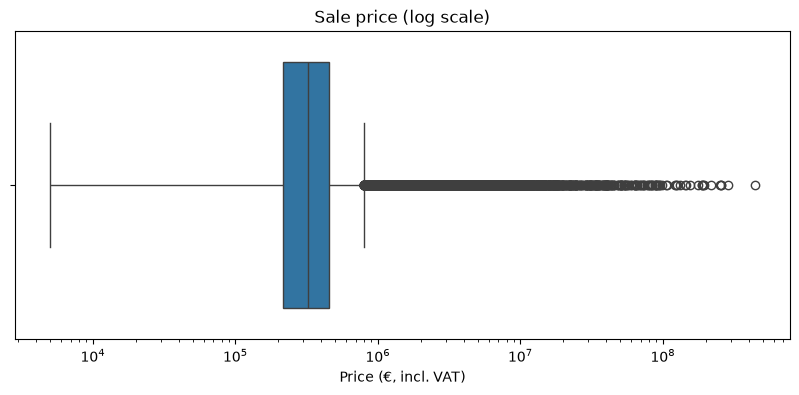

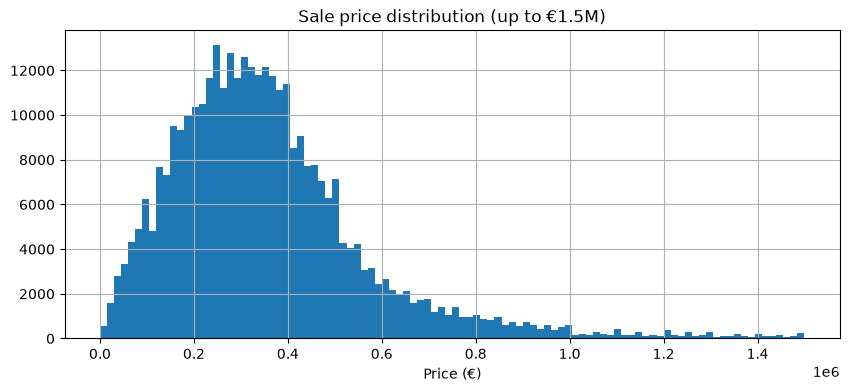

In [33]:
# Boxplot of price (log scale, because prices are very spread out)
plt.figure(figsize=(10, 4))
sns.boxplot(x=ppr['price_incl_vat'])
plt.xscale('log')
plt.title('Sale price (log scale)')
plt.xlabel('Price (€, incl. VAT)')
plt.show()

# Histogram
plt.figure(figsize=(10, 4))
ppr['price_incl_vat'].hist(bins=100, range=(0, 1500000))
plt.title('Sale price distribution (up to €1.5M)')
plt.xlabel('Price (€)')
plt.show()

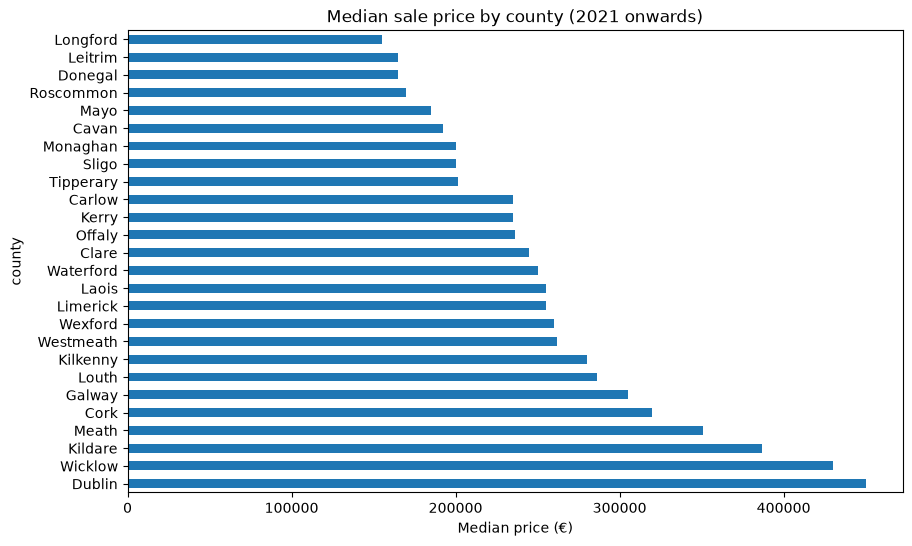

In [34]:
# Median price by county
county_price = ppr.groupby('county')['price_incl_vat'].median().sort_values(ascending=False)

plt.figure(figsize=(10, 6))
county_price.plot(kind='barh')
plt.title('Median sale price by county (2021 onwards)')
plt.xlabel('Median price (€)')
plt.show()

In [35]:
#Add year and quarter columns
#Our project joins datasets by **county + quarter**, so we create these now.
ppr['year'] = ppr['sale_date'].dt.year
ppr['quarter'] = ppr['sale_date'].dt.to_period('Q').astype(str)   # e.g. '2021Q1'

ppr[['sale_date', 'year', 'quarter']].head()

,sale_date,year,quarter
458951,2021-01-01,2021,2021Q1
458952,2021-01-01,2021,2021Q1
458953,2021-01-03,2021,2021Q1
458954,2021-01-04,2021,2021Q1
458955,2021-01-04,2021,2021Q1


In [36]:
## Step 16: Save the processed PPR data
#Saved in a new folder: `processed_dataset\property_price_dataset`. The original file is not changed.
import os

save_folder = r'C:\Users\LENOVO\OneDrive\OneDrive - National College of Ireland\Machine_learning_Project\dataSet\processed_dataset\property_price_dataset'
os.makedirs(save_folder, exist_ok=True)

save_path = save_folder + r'\ppr_2021_onwards.csv'
ppr.to_csv(save_path, index=False)

print('Saved', ppr.shape, 'to', save_path)

Saved (352379, 12) to C:\Users\LENOVO\OneDrive\OneDrive - National College of Ireland\Machine_learning_Project\dataSet\processed_dataset\property_price_dataset\ppr_2021_onwards.csv
